# Treatment Effect: A Critique — a simulation tutorial

This notebook rediscovers, by simulation, the argument of **Battey & Edgar
(2026), "Treatment effect: a critique"** (see
[`papers/battey-edgar-2026-treatment-effect-a-critique-summary.md`](../papers/battey-edgar-2026-treatment-effect-a-critique-summary.md)).

Two definitions of "treatment effect" compete in statistics:

- **Model-based** — the effect is a *stable parameter* (Δ or θ) of a correctly
  specified outcome model (Fisher's tradition, formalised by McCullagh).
- **Model-free** — the effect is the *average difference in potential
  outcomes* (eq. 3.1): $\tau_n = \frac{1}{n}\sum_i E[Y_i(1) - Y_i(0)]$,
  possibly after a monotone transform (Neyman/Rubin tradition).

The paper works under a **fictitious idealisation**: every individual is
twinned with a perfect copy, so *both* potential outcomes are observable and
each unit's baseline parameter $\gamma_i$ is known. This removes every
identification problem — confounding, missing counterfactuals — and isolates
one question: **do the two definitions even measure the same thing?**

Five worked examples answer: *sometimes* — and when they disagree, the
model-free effect depends on which units happened to be sampled.

## Setup

All logic is imported from `logic/`; this notebook only illustrates.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logic.simulation_engine import run_study, run_scenarios
from logic.battey_edgar_models import (
    GAMMA_POPULATIONS,
    LOGODDS_POPULATIONS,
    ExponentialAdditiveModel,
    ExponentialMultiplicativeModel,
    LinearAdditiveModel,
    LogisticAdditiveModel,
    WeibullMultiplicativeModel,
    make_default_examples,
)
from logic.treatment_effect_plots import (
    plot_estimate_stability,
    plot_population_sensitivity,
)

SEED = 20261009
N = 500        # units per replication
N_REPS = 300   # Monte Carlo replications

summary_rows = []  # running cross-example summary, filled as we go


def summarize(df, label, verdict):
    """Append one row of the running summary table (display only)."""
    g = df.groupby("estimator")["estimate"].agg(["mean", "std"]).round(3)
    summary_rows.append({
        "example": label,
        "model_free mean": g.loc["model_free", "mean"],
        "model_free std": g.loc["model_free", "std"],
        "model_based mean": g.loc["model_based", "mean"],
        "model_based std": g.loc["model_based", "std"],
        "verdict": verdict,
    })
    return g

## How to read what follows

For each example we report **three quantities**:

1. **analytic τₙ** — the *closed-form value* of eq. 3.1 given the realized
   baseline sample $(\gamma_i)$. This is deterministic math, not simulation:
   eq. 3.1 is an expectation.
2. **model-free estimate** — the empirical plug-in: average the (possibly
   log-transformed) outcome differences actually simulated.
3. **model-based estimate** — the MLE of the true parameter using the known
   model (and the known $\gamma_i$, available under the idealisation).

In the stability plots, each row is an estimator, dots are replications, and
the **black tick** is that estimator's reference value — *absence of a tick
means the estimator has no stable target*, which is precisely the paper's
critique.

The paper's three **compatibility conditions** (end of §4.3) — previewed here,
revisited at the end: the two definitions coincide for every sample iff
(1) treatment acts as a group transformation on the baseline distribution via
the baseline parameter, (2) the same group action describes the transformation
of the observations, and (3) no other nuisance parameter enters the relevant
expectation.

## Example 1 — linear model, additive effect (compatible)

$Y_{i0} = \gamma_i + \varepsilon_i$, $Y_{i1} = \gamma_i + \Delta +
\varepsilon_i$ — with **one shared** $\varepsilon_i$ per unit (Fisher's
*unit treatment additivity*). The paper's claim: $\tau_n = \Delta$ **exactly,
for every sample** — not merely on average. Note the shared noise: with
independent draws per arm the recovery would only hold in expectation.

In [2]:
ex1 = LinearAdditiveModel(GAMMA_POPULATIONS["moderate"], delta=2.0, sigma=1.0)
df1 = run_study(ex1, n=N, n_reps=N_REPS, seed=SEED)

print("analytic tau_n   :", df1["analytic_tau"].iloc[0])
print("spread of model-free estimates across replications:",
      df1[df1.estimator == "model_free"]["estimate"].std())
summarize(df1, "1 linear additive", "compatible (exact)")

analytic tau_n   : 2.0
spread of model-free estimates across replications: 0.0


,mean,std
estimator,,
model_based,2.0,0.0
model_free,2.0,0.0


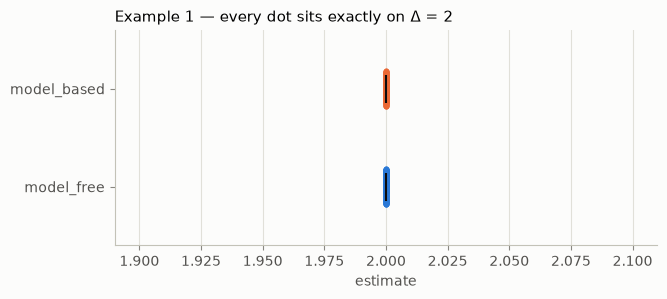

In [3]:
plot_estimate_stability(df1, title="Example 1 — every dot sits exactly on Δ = 2")
plt.show()

**Takeaway.** Zero spread: the model-free average *is* the model parameter,
replication after replication. This is the one setting where the two
definitions are the same object — and it is the setting Fisher's design-of-
experiments work actually assumed.

## Example 2 — exponential outcomes, multiplicative effect (compatible)

$Y_{i0} \sim \mathrm{Exp}(\gamma_i)$, $Y_{i1} \sim \mathrm{Exp}(\gamma_i
\theta)$. A *scale family*: after a log transform, $\tau_n = -\log\theta$
for **every** $\gamma$-sample. We report the model-free estimate back on the
$\theta$ scale via $e^{-\hat\tau}$, and the model-based MLE in closed form
($\hat\theta = n / \sum_i \gamma_i Y_{i1}$, since $\gamma_i Y_{i1} \sim
\mathrm{Exp}(\theta)$).

In [4]:
ex2 = ExponentialMultiplicativeModel(GAMMA_POPULATIONS["moderate"], theta=0.5)
df2 = run_study(ex2, n=N, n_reps=N_REPS, seed=SEED + 1)

print("analytic tau_n = -log(theta) =", round(df2["analytic_tau"].iloc[0], 4))
summarize(df2, "2 exponential ×", "compatible")

analytic tau_n = -log(theta) = 0.6931


,mean,std
estimator,,
model_based,0.500,0.022
model_free,0.505,0.041


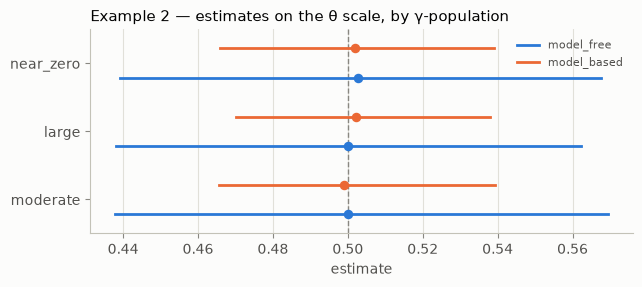

In [5]:
# tau_n is invariant to the gamma-population — swap it and nothing moves
scenarios2 = {
    pop: ExponentialMultiplicativeModel(dist, theta=0.5)
    for pop, dist in GAMMA_POPULATIONS.items()
}
sc2 = run_scenarios(scenarios2, n=N, n_reps=N_REPS, seed=SEED + 2)
plot_population_sensitivity(
    sc2, true_value=0.5,
    title="Example 2 — estimates on the θ scale, by γ-population",
)
plt.show()

In [6]:
# Convergence: the model-free plug-in tightens around theta as n grows
rows = []
for n in (50, 200, 1000, 5000):
    d = run_study(ex2, n=n, n_reps=200, seed=SEED + 3)
    s = d.groupby("estimator")["estimate"].std()
    rows.append({"n": n,
                 "model_free std": round(s["model_free"], 4),
                 "model_based std": round(s["model_based"], 4)})
pd.DataFrame(rows)

,n,model_free std,model_based std
0,50,0.1269,0.0752
1,200,0.0654,0.0320
2,1000,0.0289,0.0159
3,5000,0.0124,0.0076


**Takeaway.** Compatible: the model-free effect is just the model parameter on
another scale, and no choice of γ-population moves it. Note the model-based
MLE is visibly more efficient (smaller spread) at every n — knowing the model
buys precision even when both definitions agree.

## Example 3 — Weibull extension (semi-compatible)

Same rate structure with Weibull shape $\alpha$ (survival
$e^{-\mathrm{rate}\, y^\alpha}$): now $\tau_n = -\log\theta / \alpha$
for every sample. **Stable** — but $\theta$ and $\alpha$ are confounded in
$\tau_n$: the model-free number cannot be unscrambled into a treatment effect
without knowing $\alpha$.

### 3a — α known

In [7]:
ex3a = WeibullMultiplicativeModel(
    GAMMA_POPULATIONS["moderate"], theta=0.5, alpha=2.0, alpha_known=True
)
df3a = run_study(ex3a, n=N, n_reps=N_REPS, seed=SEED + 4)
print("analytic tau_n = -log(theta)/alpha =",
      round(df3a["analytic_tau"].iloc[0], 4))
summarize(df3a, "3 Weibull (α known)", "semi-compatible")
df3a.groupby("estimator")["estimate"].agg(["mean", "std"]).round(4)

analytic tau_n = -log(theta)/alpha = 0.3466


,mean,std
estimator,,
model_based,0.5015,0.0220
model_free,0.5027,0.0397


### 3b — α jointly estimated

The *likelihood* identifies $(\alpha, \theta)$ jointly without trouble —
the model-based route is fine. What fails is only the attempt to read a
treatment effect off the scalar $\tau_n$.

In [8]:
ex3b = WeibullMultiplicativeModel(
    GAMMA_POPULATIONS["moderate"], theta=0.5, alpha=2.0, alpha_known=False
)
df3b = run_study(ex3b, n=N, n_reps=100, seed=SEED + 5)
g = df3b.groupby("estimator")["estimate"].agg(["mean", "std"]).round(4)
print("true theta = 0.5, true alpha = 2.0,",
      "tau reference = -log(0.5)/2 =", round(np.log(2) / 2, 4))
g

true theta = 0.5, true alpha = 2.0, tau reference = -log(0.5)/2 = 0.3466


,mean,std
estimator,,
model_based,0.5014,0.0251
model_based_alpha,2.0027,0.0447
model_free,0.3480,0.0418


**Takeaway.** `model_based` recovers θ and `model_based_alpha` recovers α —
yet `model_free` (the raw τ̂) is a single number equal to $-\log\theta /
\alpha$: qualitatively sensible, stable across samples, but **not a treatment
effect on any interpretable scale unless α is known**. The paper calls this
semi-compatible.

## Example 4 — exponential outcomes, *additive* rate shift (incompatible)

The paper's key negative example. $Y_{i0} \sim \mathrm{Exp}(\gamma_i)$,
$Y_{i1} \sim \mathrm{Exp}(\gamma_i + \Delta)$ — the effect is additive on
the rate scale, a perfectly stable, well-defined Δ. But eq. 3.1 (log scale)
gives $\tau_n = -\frac{1}{n}\sum_i \log\left(\frac{\gamma_i +
\Delta}{\gamma_i}\right)$ — a quantity that **depends on which γ's were
sampled**. (Convention note: we define τ as treated-minus-control throughout,
matching example 2's $-\log\theta$; the paper prints eq. 4.1 with the
opposite sign, but the γ-dependence — the entire point — is identical.)

Fix Δ = 2 and try the paper's two extreme populations.

In [9]:
scenarios4 = {
    pop: ExponentialAdditiveModel(dist, delta=2.0)
    for pop, dist in GAMMA_POPULATIONS.items()
}
sc4 = run_scenarios(scenarios4, n=N, n_reps=N_REPS, seed=SEED + 6)
sc4.groupby(["scenario", "estimator"])["estimate"].agg(
    ["mean", "std"]).round(3)

mean    std
scenario  estimator                
large     model_based  1.998  0.408
          model_free  -0.243  0.082
moderate  model_based  1.994  0.125
          model_free  -1.116  0.081
near_zero model_based  2.007  0.092
          model_free  -3.315  0.087

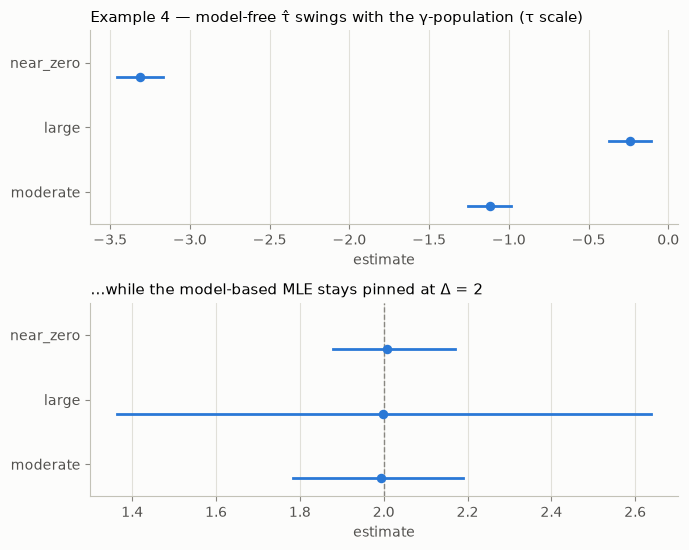

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5.6), sharex=False,
                         facecolor="#fcfcfb")
plot_population_sensitivity(
    sc4[sc4.estimator == "model_free"],
    title="Example 4 — model-free τ̂ swings with the γ-population (τ scale)",
    ax=axes[0],
)
plot_population_sensitivity(
    sc4[sc4.estimator == "model_based"], true_value=2.0,
    title="…while the model-based MLE stays pinned at Δ = 2",
    ax=axes[1],
)
fig.tight_layout()
plt.show()

In [11]:
df4 = run_study(ExponentialAdditiveModel(GAMMA_POPULATIONS["moderate"], 2.0),
                n=N, n_reps=N_REPS, seed=SEED + 7)
summarize(df4, "4 exponential +", "INCOMPATIBLE: τ̂ is population-dependent");

**Takeaway.** Same Δ = 2 in every scenario, three different "treatment
effects" from the model-free definition (−3.3 vs −1.1 vs −0.26 on the τ
scale). A study on near-zero-γ units and a study on large-γ units would report
*different effects for the same treatment* — conclusions do not generalise.
The model-based MLE recovers 2.0 regardless, because Δ is a stable parameter
of a correct model.

## Example 5 — binary outcomes, logistic model (incompatible)

$Y_{i0} \sim \mathrm{Bern}(\mathrm{expit}(\gamma_i))$, $Y_{i1} \sim
\mathrm{Bern}(\mathrm{expit}(\gamma_i + \Delta))$: Δ is a stable additive
effect on the **log-odds** scale. Eq. 3.1 on the probability scale (eq. 4.2)
again depends on the γ-sample. The model-based fit is an offset logistic GLM
(known γᵢ as offset, single coefficient = Δ).

In [12]:
scenarios5 = {
    pop: LogisticAdditiveModel(dist, delta=2.0)
    for pop, dist in LOGODDS_POPULATIONS.items()
}
sc5 = run_scenarios(scenarios5, n=N, n_reps=N_REPS, seed=SEED + 8)
sc5.groupby(["scenario", "estimator"])["estimate"].agg(
    ["mean", "std"]).round(3)

mean    std
scenario      estimator                
balanced      model_based  2.015  0.135
              model_free   0.347  0.025
common_events model_based  2.019  0.266
              model_free   0.160  0.018
rare_events   model_based  1.994  0.108
              model_free   0.226  0.024

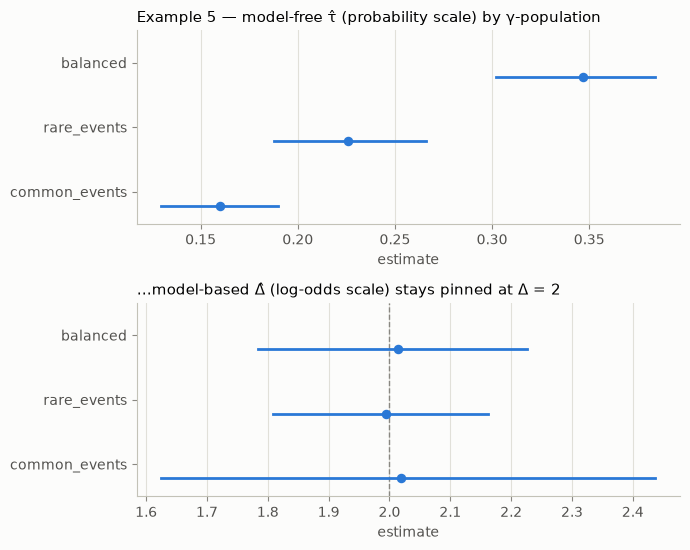

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(7, 5.6), facecolor="#fcfcfb")
plot_population_sensitivity(
    sc5[sc5.estimator == "model_free"],
    title="Example 5 — model-free τ̂ (probability scale) by γ-population",
    ax=axes[0],
)
plot_population_sensitivity(
    sc5[sc5.estimator == "model_based"], true_value=2.0,
    title="…model-based Δ̂ (log-odds scale) stays pinned at Δ = 2",
    ax=axes[1],
)
fig.tight_layout()
plt.show()

In [14]:
df5 = run_study(LogisticAdditiveModel(LOGODDS_POPULATIONS["balanced"], 2.0),
                n=N, n_reps=N_REPS, seed=SEED + 9)
summarize(df5, "5 logistic", "INCOMPATIBLE: τ̂ is population-dependent");

**Takeaway.** For rare events the probability-scale effect is small simply
because baseline probabilities are small — not because the treatment is weak.
Heterogeneity in *baselines* masquerades as heterogeneity in *effects* when
the effect is measured on an unstable scale. The paper's resolution (and Ding
& Dasgupta's observation turned around): allow units different baseline
probabilities, keep the effect stable on the log-odds scale — and model any
genuine effect heterogeneity explicitly as interactions.

## Cross-example comparison

In [15]:
pd.DataFrame(summary_rows).set_index("example")

,model_free mean,model_free std,model_based mean,model_based std,verdict
example,,,,,
1 linear additive,2.000,0.000,2.000,0.000,compatible (exact)
2 exponential ×,0.505,0.041,0.500,0.022,compatible
3 Weibull (α known),0.503,0.040,0.501,0.022,semi-compatible
4 exponential +,-1.122,0.086,2.008,0.143,INCOMPATIBLE: τ̂ is population-dependent
5 logistic,0.345,0.027,1.998,0.131,INCOMPATIBLE: τ̂ is population-dependent


In [16]:
# The same five models under two contrasting baseline populations:
# model_based columns barely move; model_free moves for examples 4-5 only.
def examples_for(pop, logodds_pop):
    return make_default_examples(population=pop,
                                 logodds_population=logodds_pop)

frames = []
for pop, lo_pop in [("near_zero", "rare_events"), ("large", "common_events")]:
    sc = run_scenarios(examples_for(pop, lo_pop), n=N, n_reps=100,
                       seed=SEED + 10)
    sc["population"] = pop
    frames.append(sc)
cross = pd.concat(frames, ignore_index=True)
(cross[cross.estimator.isin(["model_free", "model_based"])]
 .groupby(["scenario", "estimator", "population"])["estimate"].mean()
 .unstack("population").round(3))

population                                  large  near_zero
scenario                       estimator                    
ex1_linear_additive            model_based  2.000      2.000
                               model_free   2.000      2.000
ex2_exponential_multiplicative model_based  0.503      0.501
                               model_free   0.506      0.498
ex3_weibull_multiplicative     model_based  0.502      0.502
                               model_free   0.506      0.501
ex4_exponential_additive       model_based  1.968      2.003
                               model_free  -0.242     -3.316
ex5_logistic_additive          model_based  2.030      2.000
                               model_free   0.160      0.227

## Mapping back to the paper's three compatibility conditions

The two definitions coincide for every sample **iff** all three hold:

| # | Condition | Ex. 1 | Ex. 2 | Ex. 3 | Ex. 4 | Ex. 5 |
|---|-----------|-------|-------|-------|-------|-------|
| 1 | Treatment acts as a group transformation on the baseline distribution via the baseline parameter | ✓ (addition) | ✓ (scaling) | ✓ (scaling) | ✓ (rate shift) | ✓ (log-odds shift) |
| 2 | The same group action transforms the *observations* | ✓ | ✓ (after log) | ✓ (after log) | ✗ — a rate shift is not a transformation of Y | ✗ — a log-odds shift is not a transformation of a 0/1 outcome |
| 3 | No other nuisance parameter enters the relevant expectation | ✓ | ✓ | ✗ — α intrudes | ✗ — γᵢ intrudes | ✗ — γᵢ intrudes |

Conditions 1–2 together say the model is a *transformation family*. Example 3
fails only condition 3 (hence semi-compatible: stable but confounded);
examples 4–5 fail both 2 and 3 (hence sample-dependent).

## Conclusion

- The model-free definition (3.1) is **not a generalisation-free lunch**: in
  models as ordinary as logistic regression, it converts a stable, well-defined
  treatment effect into a number that changes with the sampled units.
- "Letting every unit have its own effect" is the *cause* of the instability,
  not a virtue — systematic heterogeneity belongs in the model (interactions),
  where it stays interpretable and transferable.
- Under the fictitious idealisation used throughout, **nothing was confounded
  and nothing was unobserved** — every pathology shown here is purely about
  *what the estimand is*, not about estimation difficulty.

**Next:** notebook `02_iroas_geo_experiment_case_study.ipynb` applies exactly
this lens to a real-world ratio metric — iROAS in geo experiments with budget
negativization — where "average of per-geo ratios" vs "ratio of aggregates"
replays examples 4–5, and the stable-parameter resolution replays example 2.